Import Libraries and Create Data

We need pandas for data, seaborn and matplotlib for charts, and numpy for numbers.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Creating a synthetic dataset
np.random.seed(42)
n_students = 100

data = {
      'Student_ID': range(1, n_students + 1),
      'Study_Hours': np.random.randint(1, 20, n_students),
      'Attendance_Rate': np.random.uniform(60, 100, n_students),
      'Previous_Score': np.random.randint(40, 100, n_students),
      'Exam_Score': np.random.randint(30, 100, n_students)
  }

df = pd.DataFrame(data)

# Adding some "Outliers" (extreme values) to make the Boxplot interesting
df.loc[0, 'Exam_Score'] = 5  #Extremely low score
df.loc[1, 'Exam_Score'] = 150 #Impossible high score (outlier)

print("Dataset created successfully!")
df.head()

Dataset created successfully!


,Student_ID,Study_Hours,Attendance_Rate,Previous_Score,Exam_Score
0,1,7,70.988872,91,5
1,2,15,82.449737,99,150
2,3,11,75.317075,88,75
3,4,8,98.868484,41,82
4,5,7,93.956553,40,89


Objective 1 - Outlier Identification (Boxplots)

This identifies scores that are "too far" from the average.

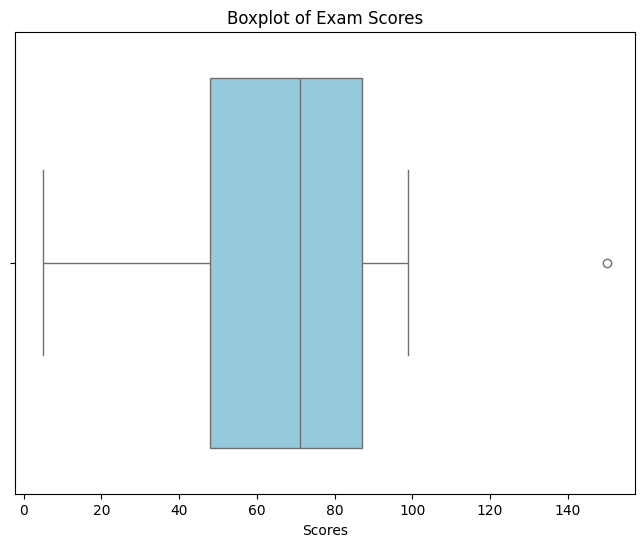

Lower Bound: -10.5, Upper Bound: 145.5
Outliers detected:
    Student_ID  Study_Hours  Attendance_Rate  Previous_Score  Exam_Score
1           2           15        82.449737              99         150


In [3]:
plt.figure(figsize=(8, 6))
sns.boxplot(x=df['Exam_Score'], color='skyblue')
plt.title('Boxplot of Exam Scores')
plt.xlabel('Scores')
plt.show()

# Calculating IQR to find outliers mathematically
Q1 = df['Exam_Score'].quantile(0.25)
Q3 = df['Exam_Score'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Exam_Score'] < lower_bound) | (df['Exam_Score'] > upper_bound)]
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")
print("Outliers detected:\n", outliers)

Objective 2 - Distribution (Histograms)

This shows if most students scored in the middle, high, or low end.

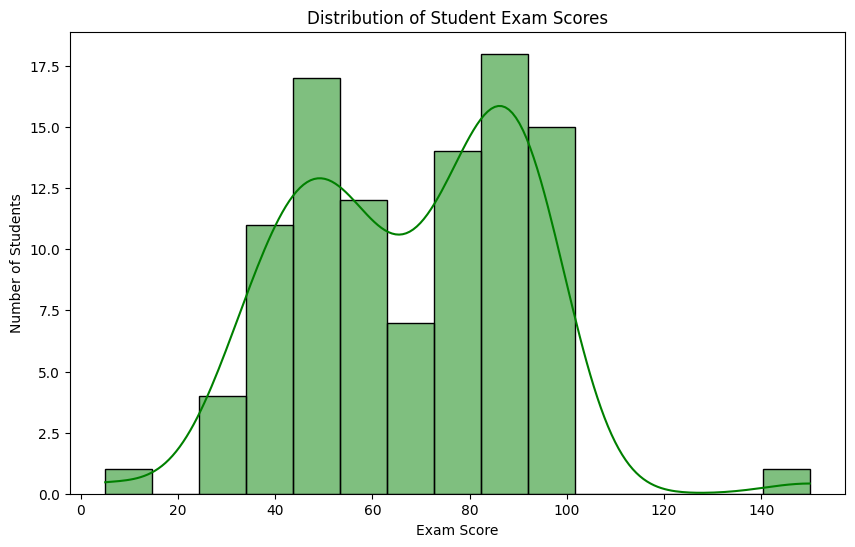

In [4]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Exam_Score'], kde=True, color='green', bins=15)
plt.title('Distribution of Student Exam Scores')
plt.xlabel('Exam Score')
plt.ylabel('Number of Students')
plt.show()

Objective 3 - Correlation Heatmap

This tells us: "Does more studying actually lead to higher grades?"

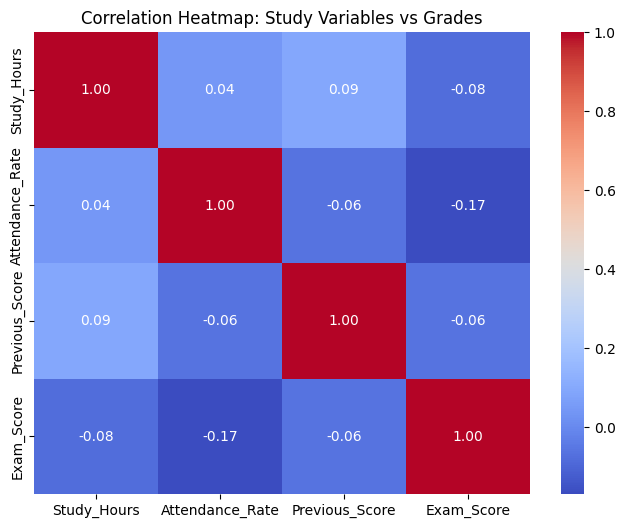

In [5]:
plt.figure(figsize=(8, 6))
# Calculate correlation only for numerical columns
correlation_matrix = df[['Study_Hours', 'Attendance_Rate', 'Previous_Score', 'Exam_Score']].corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap: Study Variables vs Grades')
plt.show()